# 02_plos: PLOS journals (PLOS ONE, PLOS Neglected Tropical Diseases, PLOS Global Public Health)

Participant-level supplementary files (PLOS requires underlying data). Found through the Europe PMC search below and downloaded from the PMC Open Access S3 bucket.

**How the journal datasets were found.** Europe PMC was searched for every open-access paper with supplementary files whose title/abstract mentions Toxoplasma, toxoplasmosis, gondii, TORCH, multiplex serology or pathogen burden (3,482 papers). Their data files (xlsx, xls, csv, sav, dta, ...) were downloaded from the PMC Open Access S3 bucket (1,407 papers had data files, 6.6 GB) and every table with >= 80 rows was scanned for a Toxoplasma result column (607 tables, 285 papers). Human, participant-level tables with at least two IgG classes were then checked by hand. Scripts: `datasets/_harvest/`.

**Same protocol for every dataset** (`datasets/common/protocol.py`): label = Toxoplasma IgG positive; every column that measures Toxoplasma itself (IgM, avidity, titre, OD, PCR, other kits) and identifiers are removed; logistic regression, random forest and XGBoost; ROC-AUC from 5-fold x 3 repeated stratified cross-validation with preprocessing inside the folds. Datasets with fewer than 20 positives or 20 negatives are catalogued but not evaluated.

**Sections:** setup → helpers → one section per dataset (where it comes from, how the label is coded, what is removed) → build and evaluate → chart. Outputs are written to `raw/`, `processed/`, `results.csv`, `DATASETS.md`.

In [1]:
# Setup: run from the repository root and load the shared protocol (datasets/common/*.ipynb)
import os, sys, warnings
os.environ['PYTHONWARNINGS'] = 'ignore'; warnings.filterwarnings('ignore')
while not os.path.isdir('datasets') and os.path.dirname(os.getcwd()) != os.getcwd():
    os.chdir('..')
sys.path.insert(0, 'scripts')          # curated loaders: scripts/external_datasets.py, us_datasets.py, europe_datasets.py
%run -i datasets/common/protocol.ipynb
%run -i datasets/common/folder_tools.ipynb
import pandas as pd
pd.set_option('display.max_colwidth', 60); pd.set_option('display.width', 200)
HERE = 'datasets/02_plos'
print('working directory:', os.getcwd())

ModuleNotFoundError: No module named 'nbformat'

**Notes on this source.** PLOS journals (PLOS ONE, PLOS NTD, PLOS Global Public Health): participant-level supplementary data files.
Found by searching Europe PMC (3,482 open-access Toxoplasma / TORCH / multiplex-serology papers with supplements), downloading
their data files from the PMC Open Access S3 bucket and scanning every table for a Toxoplasma result column.

## Helpers (curated loaders and source-specific functions)

In [2]:
import pandas as pd


import external_datasets as ex


import us_datasets as us


def per_woman(d):
    """Financial-risk study: one row per decision -> one row per woman (mean choice behaviour)."""
    for c in ['choice', 'sure', 'gain', 'loss', 'variance', 'response time', 'incentive', 'age', 'rh', 'toxo']:
        d[c] = pd.to_numeric(d[c], errors='coerce')
    g = d.groupby('id')
    return pd.DataFrame({'toxo': g.toxo.first(), 'rh_negative': g.rh.first(), 'age': g.age.first(),
                         'risky_choice_rate': g.choice.mean(), 'mean_response_time': g['response time'].mean()}).reset_index(drop=True)

## Datasets

Each cell adds one dataset to `CONFIG`: `source` = where the raw file comes from, `label` / `pos` / `neg` = how the Toxoplasma IgG result is coded, `drop` = extra columns removed (leakage, identifiers, outcomes), `loader` = a hand-written loader in `scripts/` for datasets curated earlier.

In [3]:
CONFIG = []

### indonesia_pregnant

**Seroprevalence and risk factors of T. gondii in pregnant women, Makassar**  
Indonesia · Pregnant women · DOI/ID: `10.1371/journal.pone.0245572`

In [4]:
CONFIG.append(dict(key='indonesia_pregnant', title='Seroprevalence and risk factors of T. gondii in pregnant women, Makassar',
     doi='10.1371/journal.pone.0245572', setting='Pregnant women', country='Indonesia',
     source=('pmc', 'PMC8177418'), file='pone.0245572.s001.sav', loader=ex.indonesia_pregnant))

### cameroon_hiv

**Risk factors and CD4 count in people living with HIV, Bamenda**  
Cameroon · People living with HIV · DOI/ID: `10.1371/journal.pone.0256947`

In [5]:
CONFIG.append(dict(key='cameroon_hiv', title='Risk factors and CD4 count in people living with HIV, Bamenda',
     doi='10.1371/journal.pone.0256947', setting='People living with HIV', country='Cameroon',
     source=('pmc', 'PMC8638881'), file='pone.0256947.s001.xlsx', loader=ex.cameroon_hiv))

### myanmar_slaughterhouse

**Seroprevalence and risk factors among slaughterhouse workers, Yangon**  
Myanmar · Slaughterhouse workers · DOI/ID: `10.1371/journal.pone.0284352`

In [6]:
CONFIG.append(dict(key='myanmar_slaughterhouse', title='Seroprevalence and risk factors among slaughterhouse workers, Yangon',
     doi='10.1371/journal.pone.0284352', setting='Slaughterhouse workers', country='Myanmar',
     source=('pmc', 'PMC10101469'), file='pone.0284352.s003.xlsx', loader=ex.myanmar_slaughter))

### philippines_cebu

**Seroprevalence and risk factors, general population of Cebu**  
Philippines · General population · DOI/ID: `10.1371/journal.pone.0217989`

In [7]:
CONFIG.append(dict(key='philippines_cebu', title='Seroprevalence and risk factors, general population of Cebu',
     doi='10.1371/journal.pone.0217989', setting='General population', country='Philippines',
     source=('pmc', 'PMC6561560'), file='pone.0217989.s006.xlsx', loader=ex.philippines_cebu))

### ghana_sickle_cell

**T. gondii seropositivity in sickle cell disease patients, Ho**  
Ghana · Sickle cell disease patients · DOI/ID: `10.1371/journal.pone.0346155`

In [8]:
CONFIG.append(dict(key='ghana_sickle_cell', title='T. gondii seropositivity in sickle cell disease patients, Ho',
     doi='10.1371/journal.pone.0346155', setting='Sickle cell disease patients', country='Ghana',
     source=('pmc', 'PMC13048495'), file='pone.0346155.s002.xlsx', loader=ex.ghana_sickle_cell))

### usa_baltimore_psychiatric

**Infection and inflammation in schizophrenia and bipolar disorder (Johns Hopkins)**  
USA · Schizophrenia, bipolar and control adults; plasma antibody panel · DOI/ID: `10.1371/journal.pone.0116696`

Label = Toxoplasma IgG z-score > 1.75; other-pathogen antibodies (CMV, HSV-1, HHV-6) as biomarkers.

In [9]:
CONFIG.append(dict(key='usa_baltimore_psychiatric', title='Infection and inflammation in schizophrenia and bipolar disorder (Johns Hopkins)',
     doi='10.1371/journal.pone.0116696', setting='Schizophrenia, bipolar and control adults; plasma antibody panel', country='USA',
     source=('pmc', 'PMC4363491'), file='pone.0116696.s001.txt', loader=us.johns_hopkins_baltimore,
     note='Label = Toxoplasma IgG z-score > 1.75; other-pathogen antibodies (CMV, HSV-1, HHV-6) as biomarkers.'))

### mexico_insomnia

**Toxoplasma gondii infection and insomnia: case-control seroprevalence study, Durango**  
Mexico · Adults with insomnia and matched controls · DOI/ID: `10.1371/journal.pone.0266214`

In [10]:
CONFIG.append(dict(key='mexico_insomnia', title='Toxoplasma gondii infection and insomnia: case-control seroprevalence study, Durango',
     doi='10.1371/journal.pone.0266214', setting='Adults with insomnia and matched controls', country='Mexico',
     source=('pmc', 'PMC9182222'), file='pone.0266214.s001.xls', label='Tg_IgG', pos=['positivo'], neg=['negativo'],
     drop=['numero', 'numero_control_caso1']))

### cambodia_women_multiplex

**Multiplex bead assays for parasitic diseases in a national serosurvey of women**  
Cambodia · Women 15-39 y, national population-based serosurvey · DOI/ID: `10.1371/journal.pntd.0004699`

Toxoplasma SAG2A IgG on a multiplex bead assay; inputs = region, urban, age group + antibodies to Strongyloides, malaria, cysticercosis and lymphatic filariasis.

In [11]:
CONFIG.append(dict(key='cambodia_women_multiplex', title='Multiplex bead assays for parasitic diseases in a national serosurvey of women',
     doi='10.1371/journal.pntd.0004699', setting='Women 15-39 y, national population-based serosurvey', country='Cambodia',
     source=('pmc', 'PMC4854427'), file='pntd.0004699.s003.xls', label='Toxo SAG2A_pn', pos=['1'], neg=['2'],
     drop=['stratnum', 'EA', 'weight'],
     note='Toxoplasma SAG2A IgG on a multiplex bead assay; inputs = region, urban, age group + antibodies to Strongyloides, '
          'malaria, cysticercosis and lymphatic filariasis.'))

### brazil_pregnant_vertical

**Toxoplasmosis in pregnant women and vertical transmission, Brazil**  
Brazil · Pregnant women in primary care · DOI/ID: `10.1371/journal.pone.0141700`

Every maternal / newborn laboratory result removed; inputs are age, residence, antenatal care, pregnancies, abortions.

In [12]:
CONFIG.append(dict(key='brazil_pregnant_vertical', title='Toxoplasmosis in pregnant women and vertical transmission, Brazil',
     doi='10.1371/journal.pone.0141700', setting='Pregnant women in primary care', country='Brazil',
     source=('pmc', 'PMC4641701'), file='pone.0141700.s002.xlsx', label='TOXO IgG1 Mother', pos=['reagent'], neg=['no reagent'],
     drop=['ELISA', 'PCR', 'IgA', 'Gestational risk'],
     note='Every maternal / newborn laboratory result removed; inputs are age, residence, antenatal care, pregnancies, abortions.'))

### kenya_hospital_lab

**Seroprevalence data at a private teaching hospital, Nairobi (Toxoplasma sheet)**  
Kenya · Hospital laboratory requests · DOI/ID: `10.1371/journal.pone.0204867`

Only age, sex and patient type (in/outpatient) recorded.

In [13]:
CONFIG.append(dict(key='kenya_hospital_lab', title='Seroprevalence data at a private teaching hospital, Nairobi (Toxoplasma sheet)',
     doi='10.1371/journal.pone.0204867', setting='Hospital laboratory requests', country='Kenya',
     source=('pmc', 'PMC6191086'), file='pone.0204867.s001.xlsx', sheet='Toxoplasma', label='RESULT', pos=['positive'], neg=['negative'],
     note='Only age, sex and patient type (in/outpatient) recorded.'))

### france_sleep_apnea

**Chronic toxoplasmosis and sleepiness in obstructive sleep apnea**  
France · Adults with obstructive sleep apnea · DOI/ID: `10.1371/journal.pone.0235463`

In [14]:
CONFIG.append(dict(key='france_sleep_apnea', title='Chronic toxoplasmosis and sleepiness in obstructive sleep apnea',
     doi='10.1371/journal.pone.0235463', setting='Adults with obstructive sleep apnea', country='France',
     source=('pmc', 'PMC7329112'), file='pone.0235463.s001.xlsx', label='Chronic toxoplasmosis', pos=['1'], neg=['0']))

### brazil_hiv_urine

**Detection of toxoplasmic encephalitis in HIV patients with urine nanoparticles**  
Brazil · People living with HIV · DOI/ID: `10.1371/journal.pntd.0009199`

Urine antigen tests removed (they detect the parasite).

In [15]:
CONFIG.append(dict(key='brazil_hiv_urine', title='Detection of toxoplasmic encephalitis in HIV patients with urine nanoparticles',
     doi='10.1371/journal.pntd.0009199', setting='People living with HIV', country='Brazil',
     source=('pmc', 'PMC7954332'), file='pntd.0009199.s002.xlsx', label='T. gondii serology', pos=['+'], neg=['-'],
     drop=['qPCR CSF', 'SAG1', 'GRA1', 'Mass Spec'], note='Urine antigen tests removed (they detect the parasite).'))

### brazil_leprosy_enl

**Toxoplasma infection and IgE in erythema nodosum leprosum**  
Brazil · Leprosy patients · DOI/ID: `10.1371/journal.pone.0300704`

Single input (leprosy reaction type).

In [16]:
CONFIG.append(dict(key='brazil_leprosy_enl', title='Toxoplasma infection and IgE in erythema nodosum leprosum',
     doi='10.1371/journal.pone.0300704', setting='Leprosy patients', country='Brazil',
     source=('pmc', 'PMC11168690'), file='pone.0300704.s001.xlsx', sheet='Leprosy No Reaction', label='T. gondii', pos=['p'], neg=['n'],
     note='Single input (leprosy reaction type).'))

### usa_women_financial_risk

**No association between Toxoplasma infection and financial risk taking in females**  
USA · Women tested for Toxoplasma; lottery-choice task · DOI/ID: `10.1371/journal.pone.0136716`

Trial-level file collapsed to one row per woman.

In [17]:
CONFIG.append(dict(key='usa_women_financial_risk', title='No association between Toxoplasma infection and financial risk taking in females',
     doi='10.1371/journal.pone.0136716', setting='Women tested for Toxoplasma; lottery-choice task', country='USA',
     source=('pmc', 'PMC4581702'), file='pone.0136716.s003.xlsx', label='toxo', pos=['1'], neg=['0'], prep=per_woman,
     note='Trial-level file collapsed to one row per woman.'))

## Build and evaluate

Downloads (or copies) each raw file into `raw/`, builds `processed/<dataset>.csv`, removes leakage columns, then runs logistic regression, random forest and XGBoost with 5-fold x 3 cross-validation.

In [18]:
res = run(HERE, CONFIG)

indonesia_pregnant                 n=   182 pos=   60 feats= 17 best AUC=0.865 (LogReg)


cameroon_hiv                       n=   325 pos=  164 feats= 20 best AUC=0.641 (LogReg)


myanmar_slaughterhouse             n=   139 pos=   78 feats= 46 best AUC=0.682 (LogReg)


philippines_cebu                   n=   924 pos=  244 feats= 16 best AUC=0.688 (RandomForest)


ghana_sickle_cell                  n=   156 pos=   83 feats= 10 best AUC=0.721 (LogReg)


usa_baltimore_psychiatric          n=  2660 pos=  544 feats=  9 best AUC=0.709 (LogReg)


... (3 outputs left out)

kenya_hospital_lab                 n=  1376 pos=  444 feats=  2 best AUC=0.559 (LogReg)


france_sleep_apnea                 n=    82 pos=   55 feats= 41 best AUC=0.647 (RandomForest)


brazil_hiv_urine                   n=   199 pos=  173 feats=  4 best AUC=0.673 (RandomForest)
brazil_leprosy_enl                 n=   103 pos=   76 feats=  0 best AUC=nan (not evaluated (no usable inputs))


usa_women_financial_risk           n=    79 pos=   39 feats=  3 best AUC=0.59 (XGBoost)


In [19]:
cols = ['dataset', 'country', 'n', 'positives', 'prevalence', 'n_features', 'LogReg_auc', 'RandomForest_auc', 'XGBoost_auc',
        'best_auc', 'best_model']
res[[c for c in cols if c in res]]

,dataset,country,n,positives,prevalence,n_features,LogReg_auc,RandomForest_auc,XGBoost_auc,best_auc,best_model
0,indonesia_pregnant,Indonesia,182,60,0.330,17,0.865,0.865,0.863,0.865,LogReg
1,cameroon_hiv,Cameroon,325,164,0.505,20,0.641,0.623,0.602,0.641,LogReg
2,myanmar_slaughterhouse,Myanmar,139,78,0.561,46,0.682,0.662,0.618,0.682,LogReg
3,philippines_cebu,Philippines,924,244,0.264,16,0.672,0.688,0.671,0.688,RandomForest
4,ghana_sickle_cell,Ghana,156,83,0.532,10,0.721,0.700,0.637,0.721,LogReg
5,usa_baltimore_psychiatric,USA,2660,544,0.205,9,0.709,0.691,0.676,0.709,LogReg
6,mexico_insomnia,Mexico,1154,117,0.101,8,0.736,0.725,0.702,0.736,LogReg
7,cambodia_women_multiplex,Cambodia,2150,128,0.060,25,0.518,0.571,0.544,0.571,RandomForest
8,brazil_pregnant_vertical,Brazil,473,322,0.681,9,0.477,0.527,0.543,0.543,XGBoost
9,kenya_hospital_lab,Kenya,1376,444,0.323,2,0.559,0.547,0.548,0.559,LogReg


## Chart

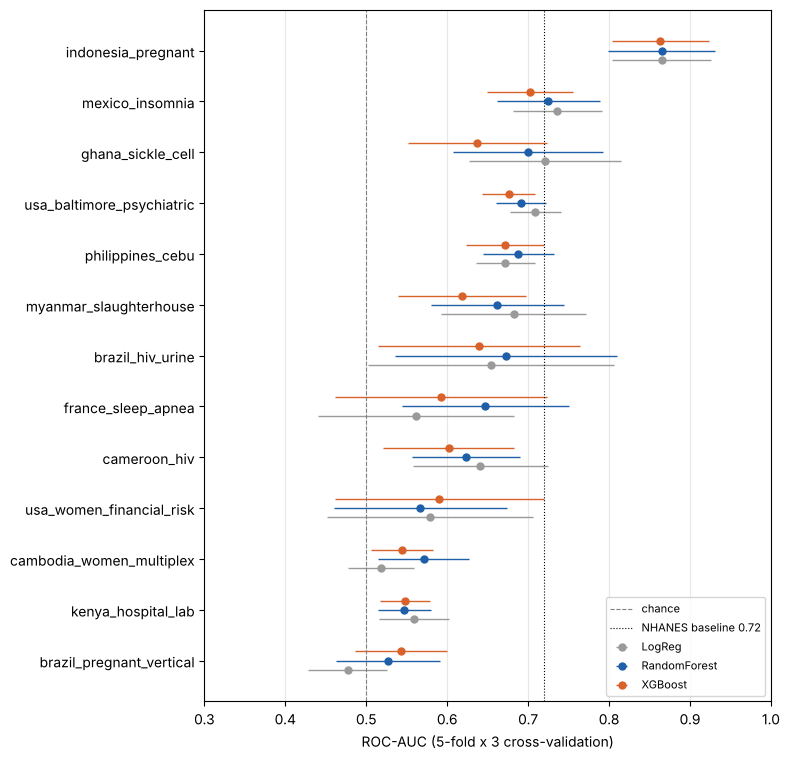

In [20]:
# ROC-AUC per dataset and model (error bars: SD over the 15 CV folds)
import matplotlib.pyplot as plt
r = res[res.best_auc.notna()].sort_values('best_auc')
if len(r):
    fig, ax = plt.subplots(figsize=(8, 0.5 * len(r) + 1.2))
    for k, (m, c) in enumerate([('LogReg', '#9a9a9a'), ('RandomForest', '#1f5fa8'), ('XGBoost', '#d9622b')]):
        ax.errorbar(r[f'{m}_auc'], [i + (k - 1) * 0.18 for i in range(len(r))], xerr=r[f'{m}_sd'], fmt='o', ms=5,
                    color=c, label=m, elinewidth=1)
    ax.axvline(0.5, ls='--', color='grey', lw=0.8, label='chance')
    ax.axvline(0.72, ls=':', color='black', lw=0.8, label='NHANES baseline 0.72')
    ax.set_yticks(range(len(r))); ax.set_yticklabels(r.dataset)
    ax.set_xlabel('ROC-AUC (5-fold x 3 cross-validation)'); ax.set_xlim(0.3, 1.0)
    ax.legend(loc='lower right', fontsize=8); ax.grid(axis='x', alpha=0.3)
    plt.tight_layout(); plt.show()

## What was removed as leakage, and the inputs used

In [21]:
res[['dataset', 'removed_as_leakage', 'features']]

,dataset,removed_as_leakage,features
0,indonesia_pregnant,,"age, trimester, parity, gravidity, abortion_history, edu..."
1,cameroon_hiv,,"age, male, married, education, farmer, years_on_art, art..."
2,myanmar_slaughterhouse,,"Slaughterhouse, age, male_flag, Education, Marital, Fami..."
3,philippines_cebu,,"age, SEX, CIV, LOCQ, EDU, PROCAT, PRSM, PRVM, cat_owner,..."
4,ghana_sickle_cell,,"age, male, education, student, married, rural, blood_tra..."
5,usa_baltimore_psychiatric,,"age, male, schizophrenia_or_bipolar, cmv_igg_z, hsv1_igg..."
6,mexico_insomnia,"Tg_IgG_UI_ml, Tg_IgM","caso_control, Igg_mayor150, N1edad, n1edad2, N2sexo, N4n..."
7,cambodia_women_multiplex,Toxo SAG2A,"province, region, regionc, urban, agecat, Strongy NIE, S..."
8,brazil_pregnant_vertical,"Had serological tests for toxoplasmosis done before?, Do...","Identification code, Age, Age brackets, City, Estate, Ba..."
9,kenya_hospital_lab,,"AGE, SEX"
